# 📘 Notebook 07: The Transformer, Attention Is All You Need

### Course: *From Papers to Practice: Landmark Deep Learning Architectures*
**Instructor:** Ioannis Tsioulis

*Paper: Vaswani, Shazeer, Parmar, Uszkoreit, Jones, Gomez, Kaiser and Polosukhin (2017)*

---

> 💡 **This notebook is already run.** Every number and picture below was produced by the code above it, and each result is followed by a comment that explains what it shows. You can read it without running anything, or choose **Runtime → Run all** in Colab.
>
> ⏱️ **Training time and limitations.** Two tiny Transformers (2 layers, 4 heads, 64 dimensions, about 100 thousand weights) learn the digit-reversal task of Notebook 06 for 2,500 steps: about **8 to 10 minutes each** on a laptop processor (this is the slowest notebook so far, mostly because the processor handles many small operations inefficiently), under a minute on a Colab GPU. The paper's base model had 6 + 6 layers, 512 dimensions and 65 million weights, trained for 12 hours on 8 GPUs to translate English to German and French. We use the **decoder-only** form of the Transformer (the input and the answer in one sequence, as in GPT) because it is shorter to write; the encoder-decoder of the paper uses exactly the same building blocks. Everything inside the attention is written by hand; only the linear layers, layer normalisation and the optimiser come from PyTorch.

## 🎯 Learning objectives

By the end of this notebook you will be able to:

- Explain **self-attention** with **queries, keys and values**, and the scaled dot product $\text{softmax}(QK^\top/\sqrt{d})\,V$
- Implement **multi-head attention**, the **causal mask** and **positional encoding** from scratch
- Assemble a **Transformer block**: attention, feed-forward network, residual connections and layer normalisation
- Train a small Transformer and compare it with the recurrent model of Notebook 06
- Show **experimentally** why positional encoding is necessary
- Read the **attention maps** of different heads

> **Prerequisites:** [Notebook 06: Sequence to Sequence with Attention](https://colab.research.google.com/github/giannis00/giannis00.github.io/blob/main/assets/jupyter/from-papers-to-practice/06_seq2seq_attention.ipynb) and [Notebook 04: ResNet](https://colab.research.google.com/github/giannis00/giannis00.github.io/blob/main/assets/jupyter/from-papers-to-practice/04_resnet.ipynb) for residual connections. Using pretrained Transformers through Hugging Face is covered in [From Python to Deep Learning and Fine-Tuning](https://giannis00.github.io/teaching/#deep-learning) and [From Words to Meaning](https://giannis00.github.io/teaching/#nlp).
>
> 🔭 **Why this notebook matters:** this is the architecture behind GPT, BERT, Claude, Gemini, AlphaFold's successors, Vision Transformers (Notebook 11) and most of modern AI. Once you have written one Transformer block yourself, the 2017 paper and every large language model built since become readable.

## 1. The paper

> 📄 A. Vaswani et al., [*Attention Is All You Need*](https://arxiv.org/abs/1706.03762), NeurIPS 2017.
>
> 📄 Decoder-only language models: A. Radford et al., [*Improving Language Understanding by Generative Pre-Training*](https://cdn.openai.com/research-covers/language-unsupervised/language_understanding_paper.pdf) (GPT), OpenAI, 2018.

### Intuition first
In Notebook 06 attention was an **add-on**: an RNN read the input step by step, and attention let the decoder look back. The 2017 paper asked: what if **attention does everything**, and there is no RNN at all?

In **self-attention**, every position of a sequence looks at every other position directly. Each position produces three vectors:
- a **query** $q$: *what am I looking for?*
- a **key** $k$: *what do I contain?*
- a **value** $v$: *what do I pass on if chosen?*

Position $i$ compares its query with every key (a dot product), turns the scores into weights with a softmax, and takes the weighted average of the values. In matrix form, for all positions at once:

$$\text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d}}\right) V$$

Dividing by $\sqrt{d}$ keeps the scores from growing with the vector size, which would make the softmax too sharp. Three consequences:
1. **No recurrence:** all positions are processed **in parallel**, which is why Transformers train so fast on GPUs.
2. **Any distance is one step:** the first and the last word are directly connected, so there is no long chain for the gradient to vanish in.
3. **No sense of order:** attention treats the input as a **set**. Word order must be added explicitly, as **positional encoding**.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import math
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.set_num_threads(4)
plt.rcParams["figure.dpi"] = 80
print("PyTorch", torch.__version__)

PyTorch 2.2.2+cpu


## 2. Scaled dot-product attention, by hand

In [2]:
def attention(q, k, v, mask=None):
    """q, k, v: (..., positions, d). Returns the outputs and the attention weights."""
    scores = q @ k.transpose(-2, -1) / math.sqrt(q.size(-1))
    if mask is not None:
        scores = scores.masked_fill(~mask, float("-inf"))
    weights = scores.softmax(-1)
    return weights @ v, weights

torch.manual_seed(0)
x = torch.randn(4, 8)                    # 4 positions, 8 dimensions
out, w = attention(x, x, x)
print("output shape:", tuple(out.shape))
print("attention weights (each row sums to 1):\n", w.round(decimals=2))
causal = torch.tril(torch.ones(4, 4, dtype=torch.bool))
out, w = attention(x, x, x, mask=causal)
print("\nwith a causal mask (no looking at future positions):\n", w.round(decimals=2))

output shape: (4, 8)
attention weights (each row sums to 1):
 tensor([[0.7700, 0.0700, 0.0200, 0.1300],
        [0.1600, 0.4200, 0.0600, 0.3600],
        [0.0100, 0.0100, 0.9800, 0.0000],
        [0.1700, 0.2300, 0.0100, 0.5800]])

with a causal mask (no looking at future positions):
 tensor([[1.0000, 0.0000, 0.0000, 0.0000],
        [0.2700, 0.7300, 0.0000, 0.0000],
        [0.0100, 0.0100, 0.9800, 0.0000],
        [0.1700, 0.2300, 0.0100, 0.5800]])


**What we see.** Each of the 4 positions gets an output of the same size (8 numbers), a mixture of all positions' values. In the weight matrix every row sums to 1; here position 3 puts **98%** of its attention on itself, while position 2 spreads it (0.42 on itself, 0.36 on position 4). With the **causal mask**, everything above the diagonal becomes exactly 0: position 1 can only see itself, position 2 only positions 1 and 2. This mask is what lets a Transformer **generate** text one token at a time, because during training no position can peek at the answer that comes after it.

## 3. Positional encoding

The paper adds to each position a vector of sines and cosines of different frequencies:

$$PE_{(p, 2i)} = \sin\!\left(p / 10000^{2i/d}\right), \qquad PE_{(p, 2i+1)} = \cos\!\left(p / 10000^{2i/d}\right)$$

Low dimensions change quickly from one position to the next, high dimensions slowly, a little like the hands of a clock. Every position gets a unique pattern, and nearby positions get similar ones.

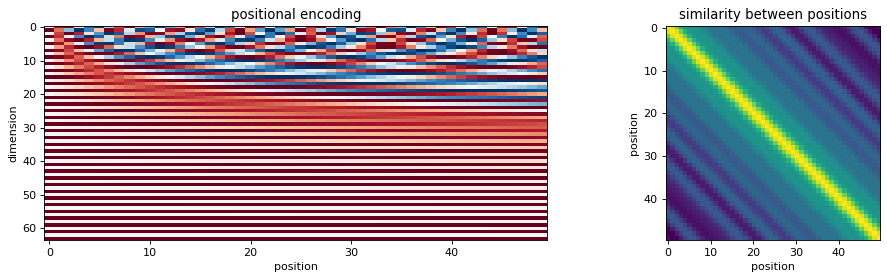

In [3]:
def positional_encoding(positions, d):
    pe = torch.zeros(positions, d)
    p = torch.arange(positions).unsqueeze(1)
    freq = torch.exp(torch.arange(0, d, 2) * (-math.log(10000.0) / d))
    pe[:, 0::2] = torch.sin(p * freq)
    pe[:, 1::2] = torch.cos(p * freq)
    return pe

pe = positional_encoding(50, 64)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
axes[0].imshow(pe.T, aspect="auto", cmap="RdBu_r")
axes[0].set_xlabel("position"); axes[0].set_ylabel("dimension"); axes[0].set_title("positional encoding")
sim = pe @ pe.T
axes[1].imshow(sim, cmap="viridis")
axes[1].set_xlabel("position"); axes[1].set_ylabel("position"); axes[1].set_title("similarity between positions")
plt.tight_layout()
plt.show()

**What we see.** Left: each column is the encoding of one position. The top rows (low dimensions) alternate quickly between red and blue, the bottom rows change slowly, so every position gets its own pattern, like a clock with hands that turn at different speeds. Right: the similarity of every pair of positions. The bright diagonal shows that each position is most similar to itself and to its **neighbours**, and the similarity fades with distance. Because of the sines and cosines, the relation between position $p$ and $p + k$ is the same rotation for every $p$, which makes relative distances easy for the model to use.

## 4. A Transformer block, and a small model

Each block has two sub-layers, each wrapped in a **residual connection** (Notebook 04) and **layer normalisation**:
1. **multi-head self-attention:** several attention "heads" in parallel, each with its own query, key and value projections, so that different heads can look for different things;
2. a small **feed-forward network** applied to each position separately.

We place layer normalisation **before** each sub-layer ("pre-norm"), the variant used by GPT-2 and most modern models because it trains more easily; the 2017 paper placed it after.

In [4]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d, heads):
        super().__init__()
        self.heads, self.dh = heads, d // heads
        self.qkv = nn.Linear(d, 3 * d)
        self.proj = nn.Linear(d, d)

    def forward(self, x, mask):
        b, n, d = x.shape
        q, k, v = self.qkv(x).view(b, n, 3, self.heads, self.dh).permute(2, 0, 3, 1, 4)
        out, w = attention(q, k, v, mask)
        return self.proj(out.transpose(1, 2).reshape(b, n, d)), w

class Block(nn.Module):
    def __init__(self, d, heads):
        super().__init__()
        self.norm1, self.norm2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.attn = MultiHeadAttention(d, heads)
        self.ff = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))

    def forward(self, x, mask):
        a, w = self.attn(self.norm1(x), mask)
        x = x + a                                # residual connection
        x = x + self.ff(self.norm2(x))           # residual connection
        return x, w

DIGITS, SEP, EOS, PAD = 10, 10, 11, 12
VOCAB, MAXLEN = 13, 64

class TinyTransformer(nn.Module):
    def __init__(self, use_positions=True, d=64, heads=4, layers=2):
        super().__init__()
        self.embed = nn.Embedding(VOCAB, d)
        self.register_buffer("pe", positional_encoding(MAXLEN, d))
        self.use_positions = use_positions
        self.blocks = nn.ModuleList([Block(d, heads) for _ in range(layers)])
        self.norm = nn.LayerNorm(d)
        self.out = nn.Linear(d, VOCAB)

    def forward(self, tokens):
        n = tokens.size(1)
        x = self.embed(tokens)                   # see the pitfall about scaling below
        if self.use_positions:
            x = x + self.pe[:n]
        causal = torch.tril(torch.ones(n, n, dtype=torch.bool))
        maps = []
        for block in self.blocks:
            x, w = block(x, causal)
            maps.append(w)
        return self.out(self.norm(x)), maps

count = lambda m: sum(p.numel() for p in m.parameters())
print("weights:", f"{count(TinyTransformer()):,}")

weights: 101,773


**What we see.** The whole model has **101,773** weights, about the size of the seq2seq models of Notebook 06 (95 to 124 thousand). The positional encoding adds none: it is a fixed table, not learned.

## 5. Training on the reversal task

The input and the answer form **one** sequence: the digits, a separator, then the reversed digits and an end symbol. The model is trained to predict every next token, but the loss counts only the answer part. At test time we give it the digits and the separator and let it write the answer one token at a time.

In [5]:
def make_batch(n, shortest, longest):
    rows = []
    for _ in range(n):
        seq = [random.randrange(DIGITS) for _ in range(random.randint(shortest, longest))]
        rows.append((seq, seq + [SEP] + seq[::-1] + [EOS]))
    width = max(len(full) for _, full in rows)
    tokens = torch.full((n, width), PAD)
    target = torch.full((n, width), PAD)
    for i, (seq, full) in enumerate(rows):
        tokens[i, :len(full)] = torch.tensor(full)
        answer_start = len(seq) + 1
        target[i, answer_start - 1:len(full) - 1] = torch.tensor(full[answer_start:])   # predict the next token
    return tokens, target

def train(use_positions, steps=2500):
    torch.manual_seed(0); random.seed(0)
    model = TinyTransformer(use_positions)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3)
    warmup = torch.optim.lr_scheduler.LambdaLR(opt, lambda step: min(1.0, (step + 1) / 200))   # the paper's warm-up
    start = time.time()
    for _ in range(steps):
        tokens, target = make_batch(64, 3, 20)
        logits, _ = model(tokens)
        loss = F.cross_entropy(logits.reshape(-1, VOCAB), target.reshape(-1), ignore_index=PAD)
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); warmup.step()
    print(f"{'with' if use_positions else 'WITHOUT'} positional encoding: trained in {time.time() - start:.0f} s")
    return model

def generate(model, seq):
    tokens = torch.tensor([seq + [SEP]])
    with torch.no_grad():
        for _ in range(len(seq) + 1):
            nxt = model(tokens)[0][0, -1].argmax().item()
            tokens = torch.cat([tokens, torch.tensor([[nxt]])], 1)
    return tokens[0, len(seq) + 1:].tolist()

def evaluate(model, lengths=(4, 8, 12, 16, 20, 24), n=200):
    random.seed(123)
    rows = {}
    for length in lengths:
        exact = 0
        for _ in range(n):
            seq = [random.randrange(DIGITS) for _ in range(length)]
            exact += generate(model, seq) == seq[::-1] + [EOS]
        rows[length] = exact / n
    return rows

with_pe = train(True)
without_pe = train(False)
results = pd.DataFrame({"with positional encoding": evaluate(with_pe), "without positional encoding": evaluate(without_pe)})
results.index.name = "length"
results.round(3)

with positional encoding: trained in 448 s


WITHOUT positional encoding: trained in 454 s


,with positional encoding,without positional encoding
length,,
4,1.000,0.975
8,1.000,0.595
12,0.975,0.085
16,0.960,0.000
20,0.895,0.000
24,0.000,0.000


**What we see.** Two clear results:
- **With positional encoding**, the Transformer reverses **100%** of 4- and 8-digit sequences, **97.5%** at 12, **96%** at 16 and **89.5%** at 20 digits, a little better than the attention RNN of Notebook 06 at the same lengths (99%, 98%, 95%, 92%, 91%). But at **24 digits**, longer than anything in training, it gets **0%**, while the RNN with attention still managed 86%. The Transformer has never seen positions beyond about 41 in its combined sequence, and its use of absolute positions does not extrapolate. Generalising to longer inputs is a known weakness of absolute positional encodings; modern models use **relative** position methods partly for this reason.
- **Without positional encoding**, accuracy collapses with length: **97.5%** at 4 digits, **60%** at 8, **8.5%** at 12, **0%** beyond. To reverse, the model must know *where* each digit is, and attention alone treats the input as a bag of tokens. It still manages short sequences because the **causal mask** leaks a little positional information (a position can count how many tokens it is allowed to see), but that weak signal does not scale.

## 6. What do the heads look at?

input : 5 2 6 0 1 8 1 5 9 0 8 3
output: 3 8 0 9 5 1 8 1 0 6 2 5 end


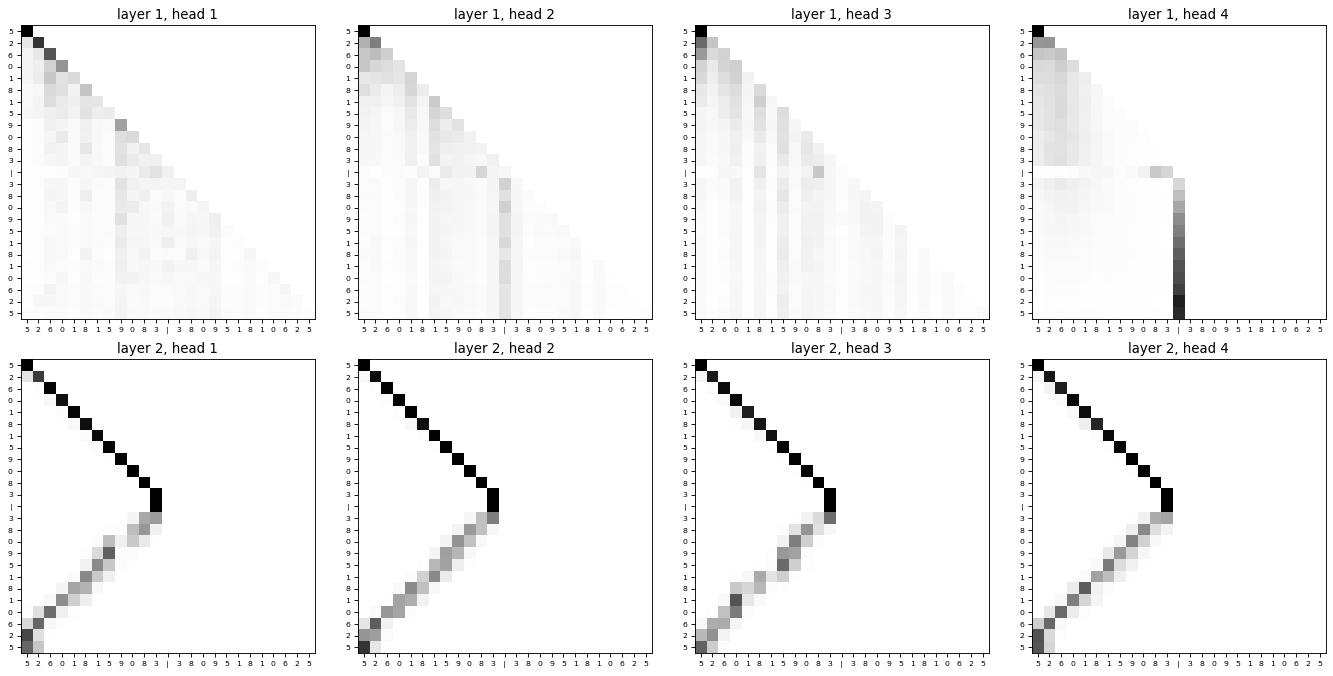

In [6]:
random.seed(7)
seq = [random.randrange(DIGITS) for _ in range(12)]
answer = generate(with_pe, seq)
tokens = torch.tensor([seq + [SEP] + answer[:-1]])
with torch.no_grad():
    _, maps = with_pe(tokens)
labels = [str(t) if t < 10 else "|" for t in tokens[0].tolist()]
print("input :", " ".join(map(str, seq)))
print("output:", " ".join(str(t) if t < 10 else "end" for t in answer))

fig, axes = plt.subplots(2, 4, figsize=(17, 8.5))
for layer in range(2):
    for head in range(4):
        ax = axes[layer, head]
        ax.imshow(maps[layer][0, head].numpy(), cmap="Greys")
        ax.set_title(f"layer {layer + 1}, head {head + 1}")
        ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, fontsize=7)
        ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=7)
plt.tight_layout()
plt.show()

**What we see.** The model wrote the correct reversal. The heads of **layer 1** look mostly backwards in diffuse ways; one of them (head 4) has learned to put all its attention on the **separator** symbol from every position of the answer, a landmark from which the rest can be counted. The heads of **layer 2** draw a striking **V**: while reading the input, each position looks at itself (the descending diagonal); after the separator, each answer position looks at the input digit it must copy next, walking backwards from the last digit to the first (the ascending branch). This is the reversal algorithm, discovered by the model from examples and clearly readable in its attention maps; the same anti-diagonal alignment as in Notebook 06, now found by self-attention alone.

## ⚠️ Common pitfalls

- **Forgetting positional information.** Without it, self-attention cannot tell "dog bites man" from "man bites dog" (Section 5).
- **Forgetting the causal mask** in a model that generates text: during training it would simply read the next token instead of predicting it.
- **Mixing up shapes.** Multi-head attention reshapes *(batch, positions, d)* into *(batch, heads, positions, d / heads)*; most bugs live in these reshapes. Print shapes.
- **Copying a detail without its context.** The paper multiplies the token embeddings by $\sqrt{d}$ before adding the positional encoding, because its embeddings start very small. PyTorch's `nn.Embedding` starts with values of size about 1, so the same multiplication made the tokens about **eight times** louder than the positions. In an early version of this notebook that drowned the positional signal, and the model barely learned to reverse 8 digits. Removing the factor fixed it.
- **Leaving out the $\sqrt{d}$ scaling of the attention scores.** With large vectors, unscaled scores make the softmax put all weight on one position, and gradients vanish.
- **Believing attention costs nothing.** Every position looks at every other, so the cost grows with the **square** of the sequence length; this is why long documents are expensive for language models.

## ✏️ Exercises

### Exercise 1 (Remove the scaling)
In `attention`, remove the division by `math.sqrt(q.size(-1))`. For random vectors of dimension 8 and 512, compare the largest attention weight in each row, with and without scaling. What happens to the softmax?

In [7]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
torch.manual_seed(0)
for d in [8, 512]:
    q, k = torch.randn(10, d), torch.randn(10, d)
    scaled = (q @ k.T / math.sqrt(d)).softmax(-1).max(-1).values.mean()
    unscaled = (q @ k.T).softmax(-1).max(-1).values.mean()
    print(f"d = {d}: mean largest weight, scaled {scaled:.2f}, unscaled {unscaled:.2f}")
```

*Without scaling, dot products of 512-dimensional vectors are large, and the softmax puts almost all the weight on a single position. The attention becomes a hard choice whose gradient is almost zero. Dividing by the square root of the dimension keeps the scores in a range where learning works.*
</details>

### Exercise 2 (One head or four?)
Train a model with `heads=1` (and the same `d=64`) and compare its accuracy by length with the four-head model.

In [8]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
class OneHead(TinyTransformer):
    def __init__(self):
        super().__init__(True, heads=1)

torch.manual_seed(0); random.seed(0)
one = OneHead()
opt = torch.optim.AdamW(one.parameters(), lr=1e-3)
for _ in range(2500):
    tokens, target = make_batch(64, 3, 20)
    loss = F.cross_entropy(one(tokens)[0].reshape(-1, VOCAB), target.reshape(-1), ignore_index=PAD)
    opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(one.parameters(), 1.0); opt.step()
print({k: round(v, 3) for k, v in evaluate(one, n=100).items()})
```

*With one head and the same size, the model learns much less in the same number of steps (in our run it reverses well under half of even the 4-digit sequences). The maps of Section 6 suggest why: the four-head model divides the work, one head finding the separator and others tracking positions, while a single head must do everything with one attention pattern per layer. Multiple heads let one position gather several kinds of information at once (in language: the subject of the verb, the previous word, the matching bracket). The total size is the same; heads split it into independent views.*
</details>

### Exercise 3 (Count the cost)
For a sequence of length $n$ and dimension $d$, the attention scores form an $n \times n$ matrix in every head and layer. Compute how many scores a model with 32 layers and 32 heads computes for $n$ = 1,000, 10,000 and 100,000 tokens.

In [9]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
for n in [1_000, 10_000, 100_000]:
    print(f"n = {n:>7,}: {32 * 32 * n * n:,} attention scores")
```

*Ten times longer input means one hundred times more scores. This quadratic cost is the main reason why long contexts are expensive, and why research on efficient attention is so active.*
</details>

## 🔑 Key takeaways

- **Self-attention** compares every position with every other through queries and keys and mixes their values: $\text{softmax}(QK^\top/\sqrt{d})V$.
- With no recurrence, Transformers process positions **in parallel** and connect any two positions in one step.
- Attention has **no sense of order**; **positional encoding** supplies it, and without it the model cannot reverse a sequence.
- A Transformer block is attention plus a feed-forward network, each wrapped in a **residual connection** and **layer normalisation**.
- Different **heads** learn different patterns, which can be read from their attention maps.

---
**Next:** *Notebook 08: Autoencoders and Variational Autoencoders*, where a network learns to compress images into a few numbers, and then to create new ones.

---
*© Ioannis Tsioulis. *From Papers to Practice: Landmark Deep Learning Architectures*. Prepared for educational use.*